# Calculating the similarity matrix and using it to fit an SVM

**Note:** This is the new version of the code, using scikit-learn instead of Turi Create (which was deprecated).
If you wish to see the original code in Turi Create that appears in the first edition of the book, please check [here](https://github.com/luisguiserrano/manning/blob/master/Chapter_11_Support_Vector_Machines/DEPRECATED_Calculating_similarities.ipynb).

### Importing packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC

### Plotting functions

In [2]:
# This function plots the points
def plot_points(X, y):
    X = np.array(X)
    y = np.array(y)
    spam = X[np.argwhere(y==1)]
    ham = X[np.argwhere(y==0)]
    plt.scatter([s[0][0] for s in spam],
                   [s[0][1] for s in spam],
                   s = 35,
                   color = 'cyan',
                   edgecolor = 'k',
                   marker = '^')
    plt.scatter([s[0][0] for s in ham],
                   [s[0][1] for s in ham],
                   s = 25,
                   color = 'red',
                   edgecolor = 'k',
                   marker = 's')
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.legend(['label 1','label 0'], loc='upper left', bbox_to_anchor=(1.02, 1))
    
def plot_model(X, y, model=None):
    X = np.array(X)
    y = np.array(y)
    plot_step = 0.01
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step),
                         np.arange(y_min, y_max, plot_step))

    grid = np.c_[xx.ravel(), yy.ravel()]

    # compute prediction for each grid point
    Z = np.array([model(p) for p in grid])
    Z = Z.reshape(xx.shape)

    # black curve where prediction = 0
    plt.contour(xx, yy, Z, levels=[0], colors='k', linewidths=3)

    # plot original points
    plot_points(X, y)

    # red for negative, blue for positive
    plt.contourf(xx, yy, Z,
                 levels=[-1e9, 0, 1e9],
                 colors=['red', 'blue'],
                 alpha=0.2)

    plt.show()

In [3]:
data = pd.DataFrame({
    'x1': [0,-1,0,0,1,-1,1],
    'x2': [0,0,-1,1,0,1,-1],
    'y': [0,0,0,1,1,1,1]
})

In [4]:
data[['x1','x2']]

,x1,x2
0,0,0
1,-1,0
2,0,-1
3,0,1
4,1,0
5,-1,1
6,1,-1


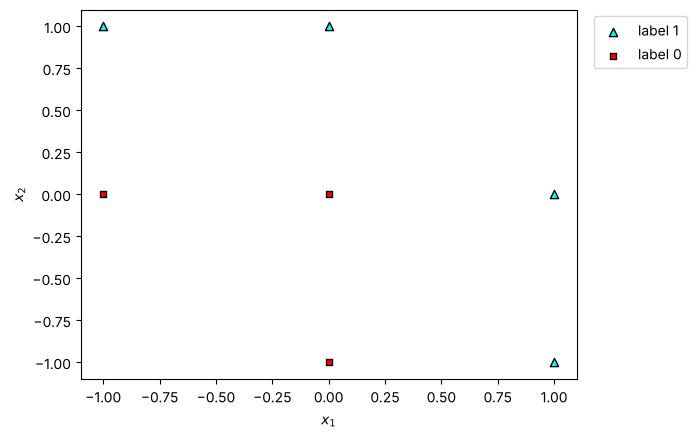

In [5]:
plot_points((data[['x1','x2']]), (data['y']))

### Calculating the similarity matrix

In [6]:
def similarity(x, y):
    return np.exp(-(x[0]-y[0])**2-(x[1]-y[1])**2)

In [7]:
data_with_similarities = data.copy()

# Compute all pairwise similarities (column Sim1 holds the similarities to point 1, and so on)
for i in range(len(data)):
    column = []
    for j in range(len(data)):
        first = [data.loc[i, 'x1'], data.loc[i, 'x2']]
        second = [data.loc[j, 'x1'], data.loc[j, 'x2']]
        column.append(similarity(first, second))
    data_with_similarities[f'Sim{i+1}'] = column

data_with_similarities

,x1,x2,y,Sim1,Sim2,Sim3,Sim4,Sim5,Sim6,Sim7
0,0,0,0,1.000000,0.367879,0.367879,0.367879,0.367879,0.135335,0.135335
1,-1,0,0,0.367879,1.000000,0.135335,0.135335,0.018316,0.367879,0.006738
2,0,-1,0,0.367879,0.135335,1.000000,0.018316,0.135335,0.006738,0.367879
3,0,1,1,0.367879,0.135335,0.018316,1.000000,0.135335,0.367879,0.006738
4,1,0,1,0.367879,0.018316,0.135335,0.135335,1.000000,0.006738,0.367879
5,-1,1,1,0.135335,0.367879,0.006738,0.367879,0.006738,1.000000,0.000335
6,1,-1,1,0.135335,0.006738,0.367879,0.006738,0.367879,0.000335,1.000000


### Fitting a (linear) SVM to the similarity matrix

In [8]:
X = data_with_similarities.drop(columns=['y'])
y = data_with_similarities['y']

svm = SVC(kernel='linear')
svm.fit(X, y)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [9]:
svm.coef_

array([[ 0.67476187,  0.67482825, -1.09720887, -0.64636729, -0.64708568,
         0.01538266,  0.01603589,  0.67770347,  0.6776795 ]])

### Plotting the classifier

In [10]:
# This function gives the prediction of the SVM on a new point

def svm_rbf_prediction(new_point):
    pairs = data[['x1', 'x2']].values.tolist()
    similarities = [similarity(new_point,pair) for pair in pairs]
    return np.dot(similarities, [-1,-1,-1,1,1,1,1])

In [11]:
# Let's verify that for the points in the dataset, it gives the correct prediction
# (i.e., positive if the label is 1, and negative if the label is -1)

pairs = data[['x1', 'x2']].values.tolist()
for p in pairs:
    print(p, svm_rbf_prediction(p))

[0, 0] -0.7293294335267746
[-1, 0] -0.9749464141121803
[0, -1] -0.9749464141121804
[0, 1] 0.9884223081103513
[1, 0] 0.9884223081103514
[-1, 1] 0.8650001793912898
[1, -1] 0.8650001793912898


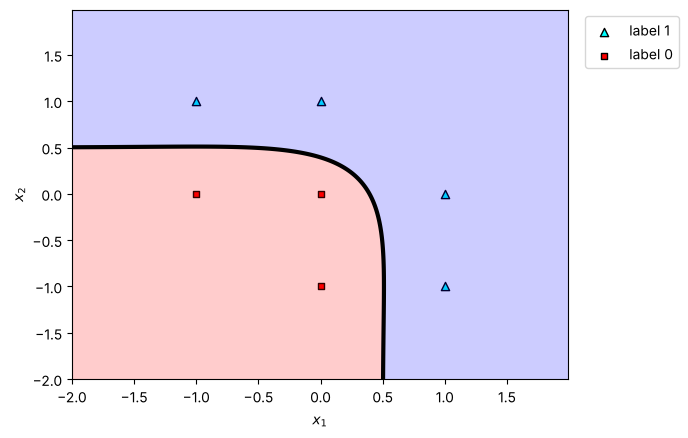

In [12]:
# Now let's plot the boundary of the model!

plot_model(X, y, svm_rbf_prediction)

## Reproducing the calculations in the book

In [13]:
# Similarity between point 1 (0, 0) and point 6 (-1, 1)
print(round(float(similarity([0, 0], [-1, 1])), 3))  # 0.135

0.135


In [14]:
# Table 11.9, rounded to three decimals
data_with_similarities.round(3)

,x1,x2,y,Sim1,Sim2,Sim3,Sim4,Sim5,Sim6,Sim7
0,0,0,0,1.000,0.368,0.368,0.368,0.368,0.135,0.135
1,-1,0,0,0.368,1.000,0.135,0.135,0.018,0.368,0.007
2,0,-1,0,0.368,0.135,1.000,0.018,0.135,0.007,0.368
3,0,1,1,0.368,0.135,0.018,1.000,0.135,0.368,0.007
4,1,0,1,0.368,0.018,0.135,0.135,1.000,0.007,0.368
5,-1,1,1,0.135,0.368,0.007,0.368,0.007,1.000,0.000
6,1,-1,1,0.135,0.007,0.368,0.007,0.368,0.000,1.000


In [15]:
# Scores of the simpler classifier (weights -1 for Sim1-Sim3, +1 for Sim4-Sim7, bias 0)
# Negative for points 1-3 (label 0), positive for points 4-7 (label 1)
for p in pairs:
    print(p, round(float(svm_rbf_prediction(p)), 3))

[0, 0] -0.729
[-1, 0] -0.975
[0, -1] -0.975
[0, 1] 0.988
[1, 0] 0.988
[-1, 1] 0.865
[1, -1] 0.865


In [16]:
# The one-dimensional example (tables 11.6 and 11.7)
xs = [-1, 0, 1]
sims = [[round(float(np.exp(-(a - b)**2)), 3) for b in xs] for a in xs]
print(sims)  # [[1.0, 0.368, 0.018], [0.368, 1.0, 0.368], [0.018, 0.368, 1.0]]
for row in sims:
    print(round(row[0] - row[1] + row[2], 3))  # 0.65, -0.264, 0.65

[[1.0, 0.368, 0.018], [0.368, 1.0, 0.368], [0.018, 0.368, 1.0]]
0.65
-0.264
0.65
